# 03 — Monitoring with MSNoise

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ORG/etna-noise-practical/blob/main/notebooks/03_autocorrelation_monitoring.ipynb)

**~20 minutes. You run the whole pipeline yourself.**

Notebook 02 asked *what is under the station*. This one asks **is it
changing?** — and does it with [MSNoise](http://www.msnoise.org), the package
the ambient-noise community actually uses, rather than with code written for
this class.

We work on **`ECPN`**, the summit station, in the **1–2 Hz** band — the
station and band of De Plaen et al. (2019), who did this at Etna with the
same method ([Front. Earth Sci. 6:251](https://doi.org/10.3389/feart.2018.00251)).

### Autocorrelation, in one paragraph

Cross-correlate the noise at two stations and you get the wave that would
travel between them. Correlate a station **with itself** and you get the
wave that goes down, reflects, and comes back — the zero-offset reflection
response (Claerbout, 1968). **One station, no pairs.** MSNoise does this
through `components_to_compute_single_station`.

> **Version note.** This runs **MSNoise 1.6.5**. Most tutorials you will find
> online — including Skience 2024 — use the development version, whose
> commands are nested: `msnoise cc compute_cc`, `msnoise cc dvv
> compute_mwcs`. In 1.6.5 they are flat: `msnoise compute_cc`, `msnoise
> compute_mwcs`. If you copy a command from elsewhere and it says "no such
> command", that is why.

In [1]:
import os, sys, shutil, subprocess
from pathlib import Path
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.path.abspath("."))
sys.path.insert(0, os.path.abspath(".."))
from etnalib import config as C

REPO = Path(C.ROOT)
SDS = REPO / "data" / "sds_teaching"
PROJ = REPO / "msnoise_live"

assert shutil.which("msnoise"), (
    "msnoise is not on PATH. You are probably in the fallback environment "
    "(etna-noise-minimal). Use the prepared results in notebook 04, or "
    "create the full environment from environment.yml.")
assert SDS.exists(), f"{SDS} missing -- run scripts/get_data.py"
SETUP = REPO / "scripts" / "msnoise_setup.py"
assert SETUP.exists(), (
    f"{SETUP} is missing. The repository is incomplete or out of date -- this "
    "notebook needs the MSNoise version of the code stack. Extract the code "
    "archive into an EMPTY directory and move your data/ folder into it; do "
    "not unpack it on top of an older copy. If you see a nested "
    f"{REPO.name}/{REPO.name}/ directory, that is what happened.")
print("msnoise:", subprocess.run(["msnoise", "--version"], capture_output=True,
                                 text=True).stdout.strip() or "ok")
print("archive:", len(list(SDS.rglob("*.D.*"))), "day files")

msnoise: ok
archive: 62 day files


## 1. Create the project

MSNoise keeps its state in a small database — which jobs exist, which have
run, what the parameters are. `db init --tech 1` makes an SQLite one in the
current directory.

Two settings do the real work here:

* `components_to_compute` is **empty** — we want nothing between stations
* `components_to_compute_single_station = ZZ` — the autocorrelation of the
  vertical

In [2]:
if PROJ.exists():
    shutil.rmtree(PROJ)          # start clean every time you run this
PROJ.mkdir(parents=True)
%cd {PROJ}

!msnoise db init --tech 1 2>&1 | tail -1
# subprocess with check, not "!", so a failure here stops the notebook
# instead of printing an error and leaving an empty project behind.
r = subprocess.run([sys.executable, str(SETUP), "--sds", str(SDS),
                    "--response", str(REPO / "data" / "processed"),
                    "--components", "ZZ", "--windsorizing=-1",
                    "--fmin", "1.0", "--fmax", "2.0"],
                   capture_output=True, text=True)
print("\n".join(r.stdout.strip().splitlines()[-4:]))
if r.returncode:
    raise SystemExit("msnoise_setup.py failed:\n" + r.stderr.strip()[-2000:])
!msnoise config set maxlag=40 2>&1 | tail -1
!msnoise config set mov_stack=2 2>&1 | tail -1
# The teaching archive is 10 Hz, so Nyquist is 5 Hz and preprocess_lowpass
# must come down from its 8 Hz default. Everything we do is in 1-2 Hz.
!msnoise config set cc_sampling_rate=10 2>&1 | tail -1
!msnoise config set preprocess_lowpass=4.0 2>&1 | tail -1

/home/raphael/WORK/PROJECTS/TESI/SEMINAR/etna-noise-practical/msnoise_live
Installation Done! - Go to Configuration Step!
config written. filters:
  filter 1: 1.0-2.0 Hz  used=True
single-station components: ZZ
AC estimator: CC   windsorizing: -1
Successfully updated parameter maxlag = 40
Successfully updated parameter mov_stack = 2
Successfully updated parameter cc_sampling_rate = 10
Successfully updated parameter preprocess_lowpass = 4.0


### The parameters, and where they come from

| setting | value | why |
|---|---|---|
| `cc_sampling_rate` | 10 Hz | the archive is already at 10 Hz, so resampling is a no-op |
| `preprocess_lowpass` | 4 Hz | must stay below the 5 Hz Nyquist |
| `maxlag` | 40 s | the measurement needs lags out to 35 s |
| `corr_duration` | 1800 s | 30-minute windows, stacked to a day |
| `windsorizing` | −1 | **one-bit**. Not the default, and it matters — see below |
| `mov_stack` | 2 | 2-day stacks, as in De Plaen et al. (2019) |
| `remove_response` | N | for one station the instrument phase cancels exactly |
| filter 1 | 1–2 Hz | the paper's band |

**On `windsorizing`.** It sets the temporal normalisation: `3.0` clips each
window at 3σ (the usual default), `-1` is one-bit, `0` is none. Etna hosts
continuous volcanic tremor at 0.5–5 Hz radiating from a fixed point at the
summit craters — the opposite of the diffuse, all-directions noise field the
method assumes. Aggressive normalisation is the standard defence, and on
this dataset it took the number of usable days from 21 to 128 out of 269.

**On 10 Hz.** The archive is decimated to 10 Hz, which halves its size. For
a 1–2 Hz measurement that costs nothing measurable: running this identical
chain at 20 Hz and at 10 Hz on the same station gives dv/v curves correlated
at **0.965**, with a median difference of **0.018 %** against a signal
standard deviation of 0.083 % and MWCS errors near 0.13 %. The sampling rate
is not what limits this. It does mean no band above ~4 Hz can be explored
from this archive — the full 100 Hz data is in `data/raw/` if you want it.

**On the lag window.** MSNoise's defaults are `dtt_lag=static`,
`dtt_minlag=5.0`, `dtt_width=30.0` — a **5–35 s** window, which happens to
be exactly what the paper used.

## 2. Scan the archive

`populate` reads the station metadata; `scan_archive` walks the waveform
files and records what exists; `new_jobs` turns that into a to-do list.

> **Order matters and nothing warns you.** `scan_archive` only looks for
> stations that are *already* in the station table. Run it before
> `populate` and it reports "Scanning 0 directories", inserts nothing, and
> exits successfully.

In [3]:
!msnoise populate 2>&1 | tail -2
!msnoise scan_archive --init 2>&1 | tail -1
!msnoise new_jobs --init 2>&1 | tail -1
!msnoise info -j 2>&1 | tail -6


Adding: IV ECPN
2026-11-17 21:05:41.342435 msnoise [pid 1432689][INFO]: It took 0.39 seconds
2026-11-17 21:05:42.565064 msnoise [INFO]: *** Finished: New Jobs ***
 STACK:
  none defined
 MWCS:
  none defined
 DTT:
  none defined


/home/raphael/anaconda3/envs/etna-noise/lib/python3.12/site-packages/msnoise/api.py:14: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


IV.ECPN 2025-12-09 23:59:59
2026-02-18 23:59:59


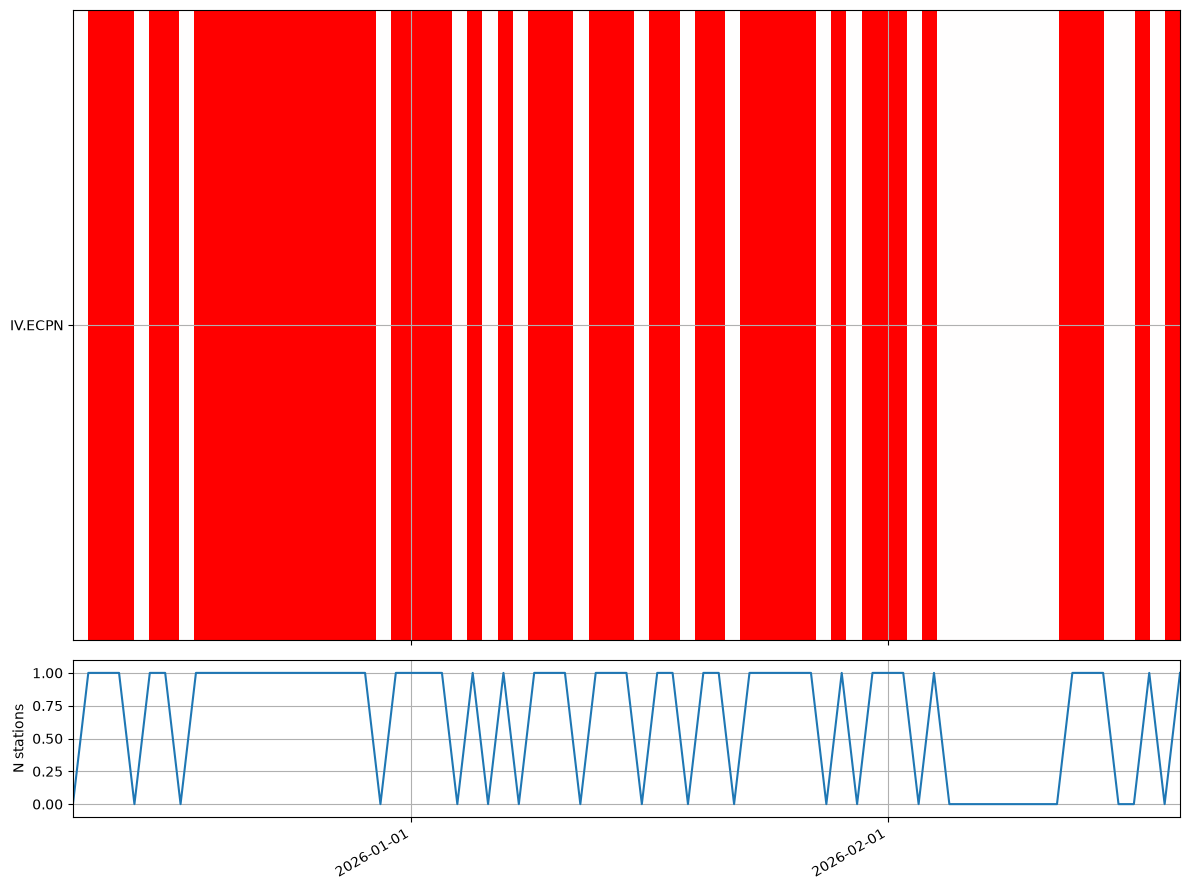

In [4]:
from msnoise.plots.data_availability import main as plot_da
plot_da(show=True)

## 3. Compute the correlations

This is the expensive step — a couple of minutes. Each day is cut into
30-minute windows, each window is one-bit normalised and autocorrelated, and
the windows are stacked into one autocorrelation per day.

In [5]:
!msnoise -t 2 compute_cc 2>&1 | grep -Ei "finished|error" | tail -2
!msnoise info -j 2>&1 | tail -5

2026-11-17 21:06:55.431134 msnoise [pid 1432821][INFO]: Job Finished. It took 0.78 seconds (preprocess: 0.28 s & process 0.50 s)
2026-11-17 21:06:55.431838 msnoise [pid 1432821][INFO]: *** Finished: Compute CC ***
  T : 62
 MWCS:
  none defined
 DTT:
  none defined


## 4. Look at what you just made — the CCF-time plot

This is the plot to spend time on. Every horizontal trace is one day's
autocorrelation; time runs up the page, lag runs across it.

New Data for IV_ECPN:IV_ECPN-ZZ-1-1


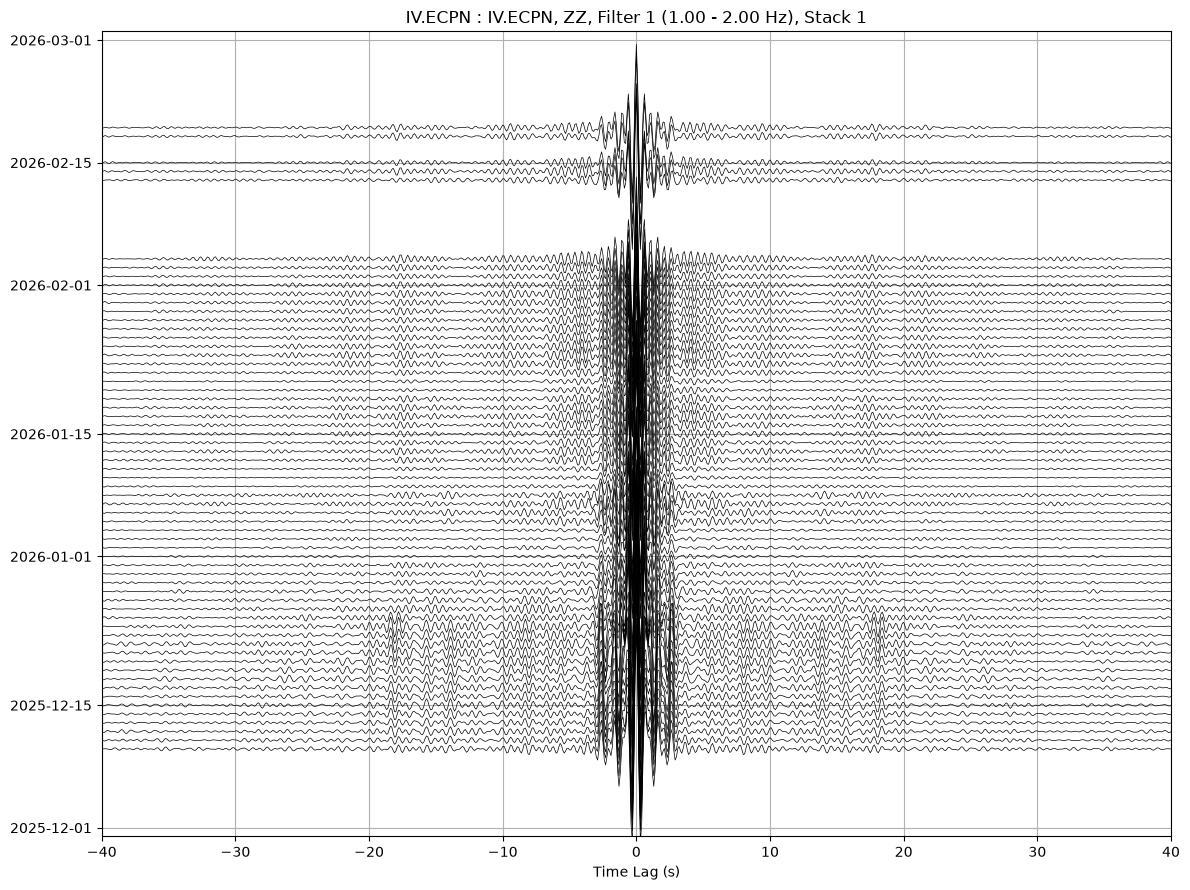

In [8]:
from msnoise.plots.ccftime import main as plot_ccftime
plot_ccftime("IV.ECPN", "IV.ECPN", filterid=1, components="ZZ",
             mov_stack=1, ampli=50, show=True)

**Read it.**

* **It is symmetric about zero lag.** It has to be: an autocorrelation is an
  even function, because correlating a signal with itself cannot distinguish
  past from future. If yours is not symmetric, something is wrong.
* **The zero-lag spike is identical every day** and carries no information.
  Never measure anything on it — which is why the lag window starts at 5 s.
* **The coda repeats, day after day, for months.** That repeatability is the
  entire basis of the method. Waves that have bounced around for 10 seconds
  have sampled the medium far more thoroughly than a direct arrival, so a
  *tiny* velocity change produces a *measurable* shift out there.

Try `envelope=True`, or `refilter="1:1.5"`, and see what changes.

## 5. Stack: the reference, then the moving stacks

dv/v is always measured **relative to something**. `stack -r` builds the
reference from the whole period; `stack -m` builds the 2-day moving stacks
that get compared against it.

The `reset STACK` in between is not optional — MSNoise deliberately leaves
the stack jobs "in progress" after the reference so you can re-run them for
the moving stacks.

In [9]:
!msnoise stack -r 2>&1 | tail -2
!msnoise reset STACK 2>&1 | tail -1
!msnoise -t 2 stack -m 2>&1 | grep -Ei "finished|error" | tail -1

2026-11-17 21:09:31.777631 msnoise [pid 1433126][INFO]: You just finished REF stacking, remember to reset the STACK jobs if you need to compute a MOV stacks. Run 'msnoise reset STACK' when all process have finished.
2026-11-17 21:09:31.777686 msnoise [pid 1433126][INFO]: The current STACK jobs have been intentionnaly left 'I'n progress so they can be reset.
  import pkg_resources


New Data for IV_ECPN:IV_ECPN-ZZ-1-2


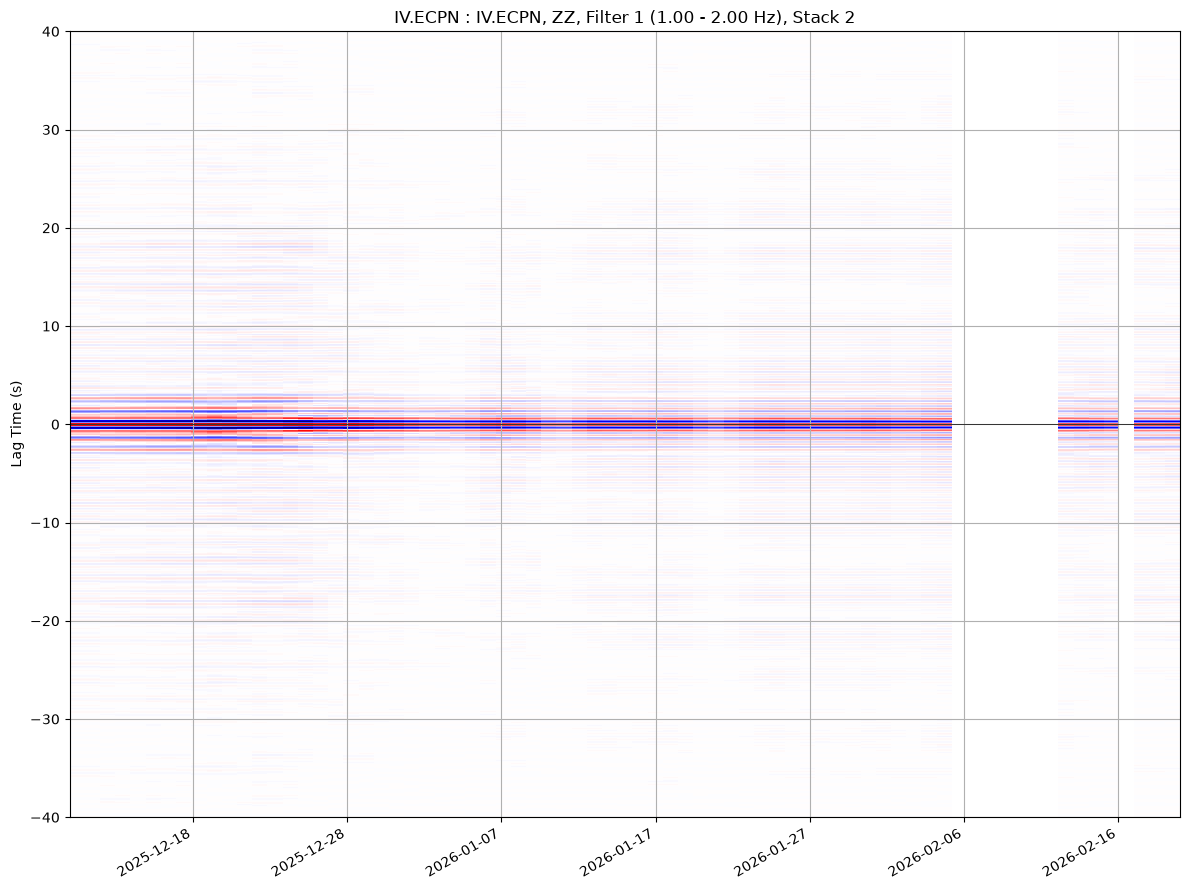

In [10]:
from msnoise.plots.interferogram import main as plot_ifg
plot_ifg("IV.ECPN", "IV.ECPN", filterid=1, components="ZZ",
         mov_stack=2, show=True)

The interferogram is the same data as an image rather than as wiggles.
Vertical stripes that stay put mean a stable medium; a stripe that leans
means the arrival is moving in time, which is what dv/v measures.

## 6. Measure: MWCS, then dt/t

**MWCS** (moving-window cross-spectral analysis) slides a short window along
the coda and, in each one, measures the time shift `dt` between this stack
and the reference from the slope of the cross-spectral phase.

**`compute_dtt`** then regresses those `dt` against lag time `t`. For a
velocity change spread uniformly through the medium that regression is a
straight line through the origin, and

$$\frac{dv}{v} = -\frac{dt}{t}$$

A point is thrown away if its error exceeds `dtt_maxerr` (0.1 s) or its
coherence is below `dtt_mincoh`.

In [14]:
!msnoise config set dtt_width=15

/home/raphael/anaconda3/envs/etna-noise/lib/python3.12/site-packages/msnoise/scripts/msnoise.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Successfully updated parameter dtt_width = 15


In [15]:
#!msnoise config set dtt_mincoh=0.6 2>&1 | tail -1

!msnoise -t 2 compute_mwcs 2>&1 | grep -Ei "finished|error" | tail -1
!msnoise compute_dtt 2>&1 | grep -Ei "finished|error" | tail -1

2026-11-17 21:12:39.546386 msnoise [pid 1433543][INFO]: *** Finished: Compute MWCS ***
2026-11-17 21:12:41.411537 msnoise [pid 1433547][INFO]: *** Finished: Compute DT/T ***


New Data for IV_ECPN_IV_ECPN-ZZ-1-2
18
<class 'pandas.core.frame.DataFrame'>
t              -34.0     -30.0     -26.0     -22.0     -18.0     -14.0  \
2025-12-10  0.027712  0.002524  0.002743 -0.012986 -0.028086 -0.005362   
2025-12-11  0.027712  0.002524  0.002743 -0.012986 -0.028086 -0.005362   
2025-12-12  0.008905  0.010170 -0.060086 -0.009718 -0.019270 -0.007384   
2025-12-13 -0.061639  0.018545 -0.083396 -0.012411 -0.015408 -0.004002   
2025-12-14 -0.053185  0.015738 -0.021001 -0.007273 -0.015329 -0.005934   
...              ...       ...       ...       ...       ...       ...   
2026-02-16 -0.012726 -0.021943  0.028754  0.021243  0.042989  0.017623   
2026-02-17       NaN       NaN       NaN       NaN       NaN       NaN   
2026-02-18  0.471337 -0.037408  0.014008  0.047888  0.553515  0.021448   
2026-02-19  0.547337 -0.039143  0.018939  0.049217  0.057369  0.572655   
2026-02-20 -0.036470 -0.028731  0.023477  0.048616  0.063784  0.593045   

t              -10.0     -6.0     

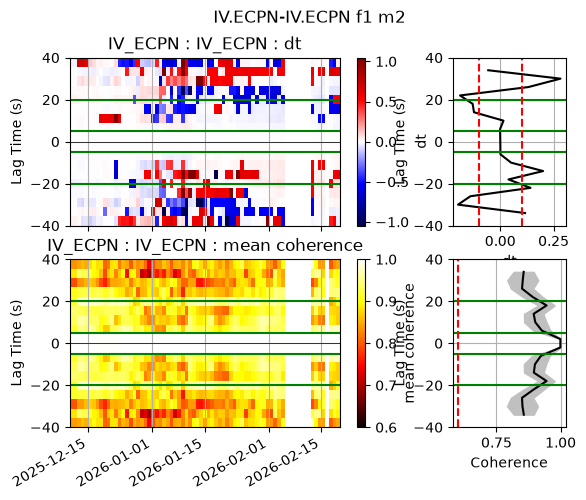

In [16]:
from msnoise.plots.mwcs import main as plot_mwcs
# mov_stack=2 here, not 1: MWCS and DTT are written per moving stack, and
# we configured 2-day stacks. Asking for mov_stack=1 finds no files and
# fails with a bare IndexError rather than a useful message.
plot_mwcs("IV.ECPN", "IV.ECPN", filterid=1, components="ZZ",
          mov_stack=2, show=True)

Each panel is one day: `dt` against lag time, with the fitted line. **This
is the actual measurement** — everything else is bookkeeping. A good day is
a tidy straight line through the origin. A day where the points scatter, or
where the line is straight but does not pass through the origin, is telling
you the simple picture does not hold.

2                       Pairs         M        EM         A        EA        M0  \
Date                                                                            
2025-12-10  IV_ECPN_IV_ECPN  0.000709  0.000207 -0.000431  0.003180  0.000709   
2025-12-11  IV_ECPN_IV_ECPN  0.000709  0.000207 -0.000431  0.003180  0.000709   
2025-12-12  IV_ECPN_IV_ECPN  0.000633  0.000198 -0.000118  0.002942  0.000633   
2025-12-13  IV_ECPN_IV_ECPN  0.000400  0.000210 -0.000247  0.003076  0.000400   
2025-12-14  IV_ECPN_IV_ECPN  0.000274  0.000171 -0.000282  0.002678  0.000274   

                 EM0  
Date                  
2025-12-10  0.000200  
2025-12-11  0.000200  
2025-12-12  0.000191  
2025-12-13  0.000202  
2025-12-14  0.000165  


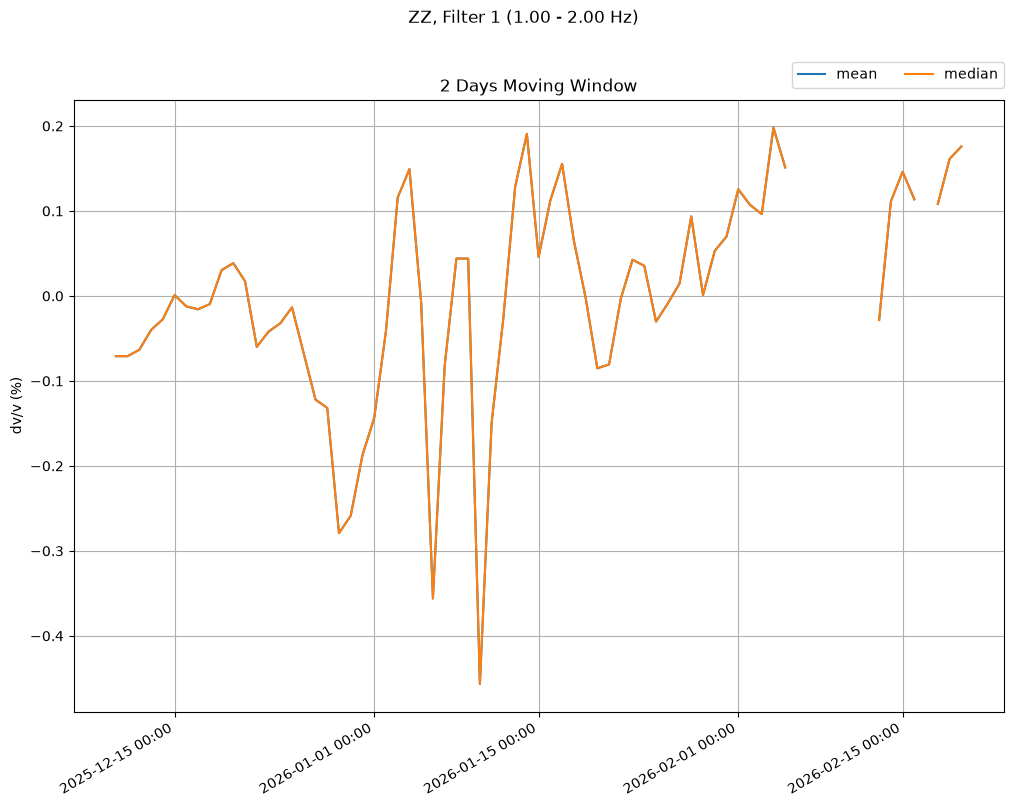

In [17]:
from msnoise.plots.dvv import main as plot_dvv
plot_dvv(mov_stack=2, dttname="M", components="ZZ", filterid=1, show=True)

In [18]:
!msnoise info

/home/raphael/anaconda3/envs/etna-noise/lib/python3.12/site-packages/msnoise/scripts/msnoise.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources

General:
 - the MSNoise module is installed in: /home/raphael/anaconda3/envs/etna-noise/lib/python3.12/site-packages
 - db.ini is present in the current directory

Database information stored in the db.ini file:
 - database type: SQLite
 - filename: msnoise.sqlite

Configuration:
 - /home/raphael/WORK/PROJECTS/TESI/SEMINAR/etna-noise-practical/data/sds_teaching exists
 - CROSS_CORRELATIONS does not exists (and that is normal because keep_all=False)

Configuration values:
   | Normal colour indicates that the default value is used
   | Green indicates "M"odified values
 M data_folder: /home/raphael/WORK/PROJECTS/TESI/SEMINAR/etn

## 7. ⚠️ The exercise: one knob each

**Work in pairs. Your demonstrator will give each pair ONE parameter.**
Change only that one, re-run from the `compute_dtt` cell (nothing before it
needs redoing — except group F, who must redo `stack -m` and
`compute_mwcs`), and write your answer on the board.

Before re-running `compute_dtt`, clear the old result: `!msnoise reset DTT`.

| group | command | what it changes |
|---|---|---|
| A | `!msnoise config set dtt_minlag=10` | start the window later in the coda |
| B | `!msnoise config set dtt_width=15` | a 5–20 s window instead of 5–35 s |
| C | `!msnoise config set dtt_mincoh=0.8` | demand better-behaved windows |
| D | `!msnoise config set dtt_maxerr=0.05` | demand smaller errors |
| E | `!msnoise config set dtt_sides=left` | one branch only, not both |
| F | `!msnoise config set mov_stack=5` *(re-run `stack -m` too, and plot with `mov_stack=5`)* | 5-day stacks |

Record three numbers: the **largest dv/v excursion**, **when** it happens,
and **how many days survived**.

Predict now, before you run it: will the seven answers agree?

### What this is really about

Everyone here runs correct code on correct data and gets a different number,
because each of you makes a different *defensible* choice. The result is not
"dv/v = x %". It is "dv/v = x %, in this band, in this lag window, relative
to this reference, with this coherence threshold". A paper that does not
state all five cannot be reproduced.

For scale: De Plaen et al. (2019) report dv/v between +0.3 % and −0.2 % at
Etna with median errors near 0.03 %. If your excursion is several per cent,
look at your coherence before you believe it.

## 8. Before you move on

1. Your dv/v is relative to a reference built from the **whole period**,
   including the eruption. What would change if you used only December?
2. The 1–2 Hz band is also Etna's volcanic tremor band, and tremor comes
   from a fixed point at the summit. The method assumes noise arriving from
   all directions. How comfortable are you?
3. Notebook 04 puts this next to the tremor amplitude and the microseism.
   Before you open it: if dv/v changes, how would you decide whether the
   *medium* changed or the *noise source* did?